Описание данных: две компонентны скорости (Vx, Vy), полученные из моделирования турбулентной струи в воде (несжимаемая среда). Снизу -- твердая стенка, сверху задается профиль вертикальной скорости в виде функции Гаусса. Справа и слева -- свободные границы.

Задание: необходимо прочитать данные двух компонент скорости из файлов. Выбрать 10 x 10 точек равномерно, и восстановить поля скоростей, включая в Loss-функцию отклонения от этих точек и невязку от уравнения непрерывности.

In [1]:
# импортировать необходимые библиотеки
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

import torch
from torch import autograd
import torch.nn as nn
import torch.optim as optim

import zipfile

Загрузить в google collab zip-архив с данными. Распоковать данные.

In [2]:
!unzip /content/PINN_data.zip

unzip:  cannot find or open /content/PINN_data.zip, /content/PINN_data.zip.zip or /content/PINN_data.zip.ZIP.


Написать функцию для чтения файлов.

Входные аргументы функции: название файла (string)

Выходные данные: массив из N строк и 3 столбцов (np.array)

In [3]:
def readfile(filename:str):
    return np.loadtxt(filename)

Проверить, что функция возвращает правильные массивы.

Вывести размеры массива.

Построить точечный график с координатами точек.

In [4]:
Vx=readfile("/content/PINN_data/Vx.txt")
Vy=readfile("/content/PINN_data/Vy.txt")
print('Vx', Vx.shape, 'Vy', Vy.shape)

FileNotFoundError: /content/PINN_data/Vx.txt not found.

Создать класс с двумя полями:
*   Vx
*   Vy

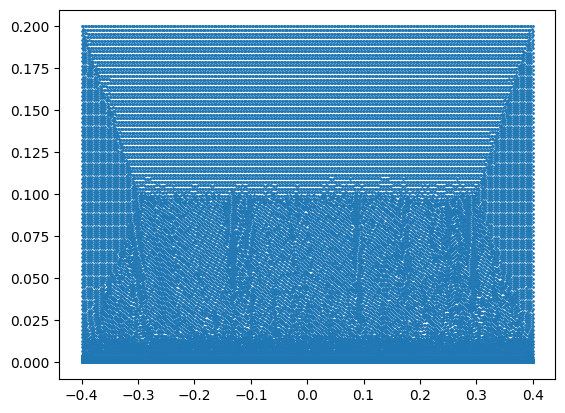

In [ ]:
plt.scatter(Vx[:,0], Vx[:,1], s=1)

In [ ]:
class velocity:
    def __init__(self, Vx=None, Vy=None):
        self.Vx = Vx
        self.Vy = Vy
velocityarray=velocity(Vx, Vy)
print(velocityarray.Vx)

[[-4.00000000e-01  1.50644288e-02 -2.02633237e+01]
 [-4.00000000e-01  1.71908668e-02 -2.00410235e+01]
 [-4.00000000e-01  4.20440232e-02 -1.56190330e+01]
 ...
 [ 4.00000000e-01  2.00000000e-01  0.00000000e+00]
 [ 4.00000000e-01  1.45621713e-01  4.91649946e-01]
 [ 4.00000000e-01  1.63747809e-01  1.61488364e-01]]


Создать функцию, которая будет аппроксимировать исходные данные на равномерную сетку.

In [ ]:
gridx = np.linspace(-0.4, 0.4, 500)
gridy = np.linspace(0.0, 0.2, 300)
gridx, gridy = np.meshgrid(gridx, gridy)

In [ ]:
def aproximaion(pointsx, pointsy,
                values, gridx, gridy):
   return griddata((pointsx, pointsy), values,
                   (gridx, gridy))



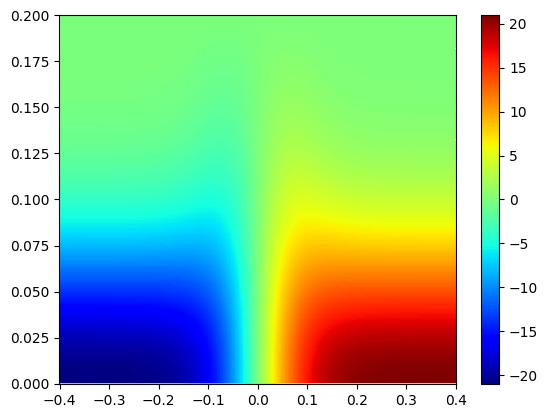

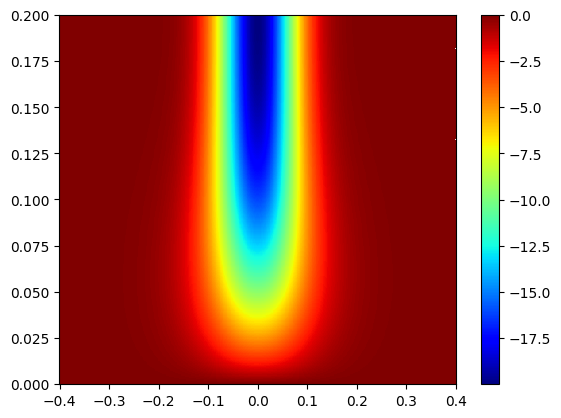

In [ ]:
vxuniform=aproximaion(Vx[:,0], Vx[:,1], Vx[:,2],
                  gridx, gridy)
vyuniform=aproximaion(Vy[:,0], Vy[:,1], Vy[:,2],
                  gridx, gridy)

plt.pcolormesh(gridx, gridy, vxuniform,cmap='jet')
plt.colorbar()
plt.show()
plt.pcolormesh(gridx, gridy, vyuniform,cmap='jet')
plt.colorbar()
plt.show()




Написать простую нейросеть, использовать шаблон как здесь:

https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html

Но использовать nn.Tanh()

Проверить, что нейросеть задана правильно.

In [5]:
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(2, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 2),

        )

    def forward(self, x):
        out = self.linear_stack(x)
        return out

Написать Loss функцию

In [ ]:
tensor = torch.rand((100,2))
neuro = PINN()
out = neuro(tensor)
print(out.shape)

torch.Size([100, 2])


In [ ]:
def batch(Vx, Vy):
    batchx = np.linspace(-0.4, 0.4, 10)
    batchy = np.linspace(0.0, 0.2, 10)
    maxx, maxy = np.meshgrid(batchx, batchy)
    ploskiyx = maxx.flatten()
    ploskiyy = maxy.flatten()
    vxuniform=aproximaion(Vx[:,0], Vx[:,1], Vx[:,2],
                  maxx, maxy)
    vxplosk = vxuniform.flatten()
    vyuniform=aproximaion(Vy[:,0], Vy[:,1], Vy[:,2],
                  maxx, maxy)
    vyplosk = vyuniform.flatten()
    return np.stack([ploskiyx, ploskiyy]).T, vxplosk, vyplosk

In [ ]:
a, b, c=batch(Vx, Vy)
a.shape

(100, 2)

In [ ]:
def asasas():
    batchx = np.linspace(-0.4, 0.4, 100)
    batchy = np.linspace(0.0, 0.2, 100)
    maxx, maxy = np.meshgrid(batchx, batchy)
    ploskiyx = maxx.flatten()
    ploskiyy = maxy.flatten()
    return np.stack([ploskiyx, ploskiyy]).T

In [ ]:
asa=asasas()
asa.shape

(10000, 2)

Написать цикл обучения

https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html#the-training-loop

In [ ]:
def train_one_epoch(epoch_index, tb_writer):
    running_loss = 0.
    last_loss = 0.

    # Here, we use enumerate(training_loader) instead of
    # iter(training_loader) so that we can track the batch
    # index and do some intra-epoch reporting
    for i, data in enumerate(training_loader):
        # Every data instance is an input + label pair
        inputs, labels = data

        # Zero your gradients for every batch!
        optimizer.zero_grad()

        # Make predictions for this batch
        outputs = model(inputs)

        # Compute the loss and its gradients
        loss = loss_fn(outputs, labels)
        loss.backward()

        # Adjust learning weights
        optimizer.step()

        # Gather data and report
        running_loss += loss.item()
        if i % 1000 == 999:
            last_loss = running_loss / 1000 # loss per batch
            print(f'  batch {i + 1} loss: {last_loss}')
            tb_x = epoch_index * len(training_loader) + i + 1
            tb_writer.add_scalar('Loss/train', last_loss, tb_x)
            running_loss = 0.

    return last_loss

Наследование в Python

In [14]:
class Parent:
    def __init__(self):
        self.value = 10

    def get_value(self):
        return self.value

class Child(Parent):
    pass

class NewChild(Parent):
    def __init__(self):
        super().__init__()  # without it we will not have `value` field
        self.new_value = 20

print(Parent().get_value(), Child().get_value(), NewChild().get_value())

print(Child().__dict__)
print(NewChild().__dict__)

10 10 10
{'value': 10}
{'value': 10, 'new_value': 20}
